# Lab: Building a Spotify-Style Music Recommender with k-Nearest Neighbors

**Course:** AI-Enabled Systems Development (Graduate)  
**Tools:** Python 3.9+, pandas, NumPy, scikit-learn, matplotlib  
**Estimated time:** 2 × 90-minute sessions (Parts 1–5 in session one, Parts 6–9 plus exercises in session two)

---

### Learning objectives

By the end of this lab you will be able to:

1. Explain why **distance in feature space** can stand in for "musical similarity", and what that assumption costs you.
2. Prepare audio-feature data for KNN (deduplication, missing values, **feature scaling**) and demonstrate why scaling is not optional.
3. Build a **content-based** recommender with `sklearn.neighbors.NearestNeighbors`, compare distance metrics, and extend it to playlist-level recommendations.
4. Use `KNeighborsClassifier` + `GridSearchCV` to pick *k* and connect it to the bias–variance trade-off.
5. Build an **item-based collaborative filter** on a sparse user–track matrix and evaluate it offline with leave-one-out Hit Rate@10 against baselines.
6. Reason about **scaling, diversity and popularity bias**, and connect exact KNN to the approximate nearest-neighbor (ANN) search that powers vector databases in the upcoming RAG module.

### Why this lab sits here in the course

Nearest-neighbor search is the hinge between classical ML and modern LLM systems. In this notebook each track is a vector of 9 audio features and "recommend" means *find the closest vectors*. In the RAG module, each document chunk becomes a vector of ~1,000 embedding dimensions and "retrieve" means... exactly the same thing. Everything you learn here about metrics, scaling, and evaluation carries straight over.

### Roadmap

| Part | Topic |
|---|---|
| 0 | Setup |
| 1 | Load the data (real Kaggle file or built-in synthetic catalog) |
| 2 | Exploratory data analysis |
| 3 | Cleaning and feature preparation |
| 4 | Why scaling matters for KNN (demo) |
| 5 | Content-based recommender with `NearestNeighbors` |
| 6 | Choosing *k* with `KNeighborsClassifier` + cross-validation |
| 7 | Item-based collaborative filtering and offline evaluation |
| 8 | Scaling up: brute force vs. trees vs. ANN |
| 9 | Packaging: a reusable `TrackRecommender` class |
| — | Exercises, challenge problems, and grading rubric |

## Part 0 — Setup

All libraries used here ship with a standard Anaconda install. If you are using a fresh virtual environment:

```bash
pip install pandas numpy scikit-learn scipy matplotlib
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

import sklearn
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


## Part 1 — Load the data

### Option A (recommended for the full experience): real Spotify data

Download the public **Spotify Tracks Dataset** from Kaggle (search "Spotify Tracks Dataset", ~114k tracks across 114 genres, file `dataset.csv`) and save it as `data/spotify_tracks.csv` next to this notebook. Its columns come from Spotify's Web API audio-features endpoint.

> ⚠️ **Instructor note:** Spotify restricted new access to its audio-features and recommendations API endpoints for new developer apps in late 2024, so students should *not* plan to pull fresh features live from the API. Use the Kaggle snapshot. Verify the dataset link and licence before distributing.

### Option B (default, works offline): a synthetic catalog

If the CSV is not found, the cell below generates a **synthetic catalog** with the *same column names and value ranges* as the Kaggle file, so every cell in this notebook runs either way. The synthetic data has built-in structure (genres and artists have characteristic "sounds"), which makes results easy to reason about.

> 📌 **Placeholder-data flag:** every number, chart, and "recommendation" in the executed outputs below comes from the synthetic catalog. Re-run on the real dataset before quoting results in lecture.

In [2]:
DATA_PATH = Path("data/spotify_tracks.csv")

AUDIO_FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]

def make_synthetic_catalog(n_per_genre=250, seed=RANDOM_STATE):
    '''Generate a Spotify-like catalog with realistic columns and genre/artist structure.'''
    r = np.random.default_rng(seed)
    # genre: (dance, energy, loudness_dB, speech, acoustic, instrumental, live, valence, tempo_bpm)
    profiles = {
        "pop":       (0.70, 0.70,  -6, 0.07, 0.15, 0.01, 0.15, 0.60, 118),
        "rock":      (0.50, 0.80,  -6, 0.05, 0.08, 0.05, 0.20, 0.50, 128),
        "hip-hop":   (0.78, 0.65,  -7, 0.28, 0.12, 0.01, 0.18, 0.50,  95),
        "edm":       (0.72, 0.88,  -4, 0.07, 0.03, 0.55, 0.20, 0.45, 126),
        "jazz":      (0.55, 0.35, -13, 0.05, 0.70, 0.45, 0.15, 0.50, 110),
        "classical": (0.30, 0.15, -22, 0.04, 0.92, 0.85, 0.12, 0.25,  95),
        "folk":      (0.52, 0.35, -11, 0.04, 0.78, 0.05, 0.13, 0.45, 112),
        "metal":     (0.40, 0.95,  -4, 0.08, 0.01, 0.20, 0.22, 0.30, 140),
        "r-n-b":     (0.68, 0.55,  -7, 0.10, 0.25, 0.01, 0.14, 0.52, 100),
        "latin":     (0.76, 0.75,  -5, 0.08, 0.20, 0.01, 0.18, 0.75, 105),
    }
    spread = np.array([0.10, 0.10, 2.5, 0.04, 0.12, 0.15, 0.08, 0.15, 12])
    adjectives = ["Midnight", "Golden", "Electric", "Silent", "Broken", "Neon", "Velvet", "Wild",
                  "Endless", "Crimson", "Paper", "Lunar", "Hollow", "Summer", "Frozen", "Burning"]
    nouns = ["Heart", "City", "River", "Dream", "Fire", "Echo", "Road", "Sky", "Ghost", "Tide",
             "Signal", "Garden", "Mirror", "Engine", "Letter", "Horizon"]
    rows, tid = [], 0
    for genre, mu in profiles.items():
        mu = np.array(mu, dtype=float)
        artists = [f"{genre.title()} Artist {i:02d}" for i in range(25)]
        artist_offset = {a: r.normal(0, spread * 0.6) for a in artists}   # each artist has a signature sound
        artist_pop = {a: r.uniform(20, 80) for a in artists}
        for _ in range(n_per_genre):
            a = artists[r.integers(len(artists))]
            f = mu + artist_offset[a] + r.normal(0, spread * 0.6)
            rows.append({
                "track_id": f"trk_{tid:05d}",
                "track_name": f"{r.choice(adjectives)} {r.choice(nouns)}",
                "artists": a,
                "album_name": f"{a} – Vol. {r.integers(1, 5)}",
                "track_genre": genre,
                "popularity": int(np.clip(r.normal(artist_pop[a], 12), 0, 100)),
                "duration_ms": int(np.clip(r.normal(215_000, 45_000), 90_000, 600_000)),
                "explicit": bool(r.random() < (0.45 if genre == "hip-hop" else 0.08)),
                "danceability": f[0], "energy": f[1], "loudness": f[2], "speechiness": f[3],
                "acousticness": f[4], "instrumentalness": f[5], "liveness": f[6],
                "valence": f[7], "tempo": f[8],
                "key": int(r.integers(0, 12)), "mode": int(r.random() < 0.6), "time_signature": 4,
            })
            tid += 1
    df = pd.DataFrame(rows)
    for c in ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]:
        df[c] = df[c].clip(0, 1)
    df["loudness"] = df["loudness"].clip(-60, 0)
    df["tempo"] = df["tempo"].clip(50, 220)
    # Mimic real-data messiness: the same track listed under two genres, plus a few missing values
    dupes = df.sample(60, random_state=seed).copy()
    dupes["track_genre"] = dupes["track_genre"].map(lambda g: "pop" if g != "pop" else "dance-pop")
    df = pd.concat([df, dupes], ignore_index=True)
    df.loc[df.sample(8, random_state=seed + 1).index, "track_name"] = np.nan
    return df

if DATA_PATH.exists():
    raw = pd.read_csv(DATA_PATH)
    raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
    DATA_SOURCE = "Kaggle Spotify Tracks Dataset"
else:
    raw = make_synthetic_catalog()
    DATA_SOURCE = "SYNTHETIC catalog (placeholder data)"

print(f"Data source: {DATA_SOURCE}")
print(f"Shape: {raw.shape}")
raw.head()

Data source: SYNTHETIC catalog (placeholder data)
Shape: (2560, 20)


,track_id,track_name,artists,album_name,track_genre,popularity,duration_ms,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
0,trk_00000,Summer River,Pop Artist 21,Pop Artist 21 – Vol. 2,pop,45,153129,True,0.973360,0.733126,-6.821652,0.069001,0.379690,0.000000,0.095280,0.727860,118.289159,8,1,4
1,trk_00001,Wild River,Pop Artist 01,Pop Artist 01 – Vol. 4,pop,100,285800,False,0.615498,0.781056,-3.314238,0.075315,0.256488,0.056860,0.108758,0.568247,113.374804,2,1,4
2,trk_00002,Neon Echo,Pop Artist 00,Pop Artist 00 – Vol. 4,pop,48,217361,False,0.733952,0.570856,-3.087609,0.098880,0.044096,0.000000,0.200653,0.612436,109.883931,8,1,4
3,trk_00003,Crimson Dream,Pop Artist 03,Pop Artist 03 – Vol. 2,pop,86,200216,False,0.731080,0.813053,-9.203756,0.115715,0.133447,0.000000,0.093087,0.497333,128.490168,4,0,4
4,trk_00004,Broken Mirror,Pop Artist 05,Pop Artist 05 – Vol. 3,pop,39,259531,False,0.791124,0.787245,-3.066139,0.114552,0.186480,0.192975,0.201374,0.543375,113.563056,7,0,4


### What do the audio features mean?

| Feature | Range | Intuition |
|---|---|---|
| `danceability` | 0–1 | Rhythm stability, beat strength, regularity |
| `energy` | 0–1 | Perceived intensity: loud, fast, noisy |
| `loudness` | ~-60–0 dB | Average loudness of the track |
| `speechiness` | 0–1 | Presence of spoken words (rap, podcasts score high) |
| `acousticness` | 0–1 | Confidence the track is acoustic |
| `instrumentalness` | 0–1 | Likelihood of *no* vocals |
| `liveness` | 0–1 | Probability of a live audience |
| `valence` | 0–1 | Musical positiveness (happy vs. sad) |
| `tempo` | ~50–220 BPM | Beats per minute |

**Key modelling assumption:** two tracks that are close in this 9-dimensional space will *sound* similar to a listener. Keep a skeptical eye on this assumption throughout. It ignores lyrics, language, era, culture, and everything else that makes people like music.

## Part 2 — Exploratory data analysis

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2560 entries, 0 to 2559
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          2560 non-null   str    
 1   track_name        2552 non-null   str    
 2   artists           2560 non-null   str    
 3   album_name        2560 non-null   str    
 4   track_genre       2560 non-null   str    
 5   popularity        2560 non-null   int64  
 6   duration_ms       2560 non-null   int64  
 7   explicit          2560 non-null   bool   
 8   danceability      2560 non-null   float64
 9   energy            2560 non-null   float64
 10  loudness          2560 non-null   float64
 11  speechiness       2560 non-null   float64
 12  acousticness      2560 non-null   float64
 13  instrumentalness  2560 non-null   float64
 14  liveness          2560 non-null   float64
 15  valence           2560 non-null   float64
 16  tempo             2560 non-null   float64
 17  key   

In [4]:
raw[AUDIO_FEATURES + ["popularity"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
danceability,2560.0,0.591,0.177,0.077,0.466,0.617,0.726,1.000
energy,2560.0,0.611,0.266,0.000,0.396,0.665,0.825,1.000
loudness,2560.0,-8.579,5.598,-28.315,-10.834,-6.969,-4.800,0.000
speechiness,2560.0,0.085,0.077,0.000,0.036,0.067,0.101,0.383
acousticness,2560.0,0.336,0.330,0.000,0.071,0.196,0.677,1.000
instrumentalness,2560.0,0.244,0.279,0.000,0.006,0.129,0.413,1.000
liveness,2560.0,0.163,0.073,0.000,0.115,0.164,0.211,0.513
valence,2560.0,0.476,0.174,0.000,0.354,0.477,0.593,1.000
tempo,2560.0,113.377,17.882,59.198,99.707,112.114,126.107,166.221
popularity,2560.0,49.853,21.296,0.000,34.000,51.000,66.000,100.000


**Observe:** `loudness` and `tempo` live on completely different scales (tens to hundreds) from the 0–1 features. Hold that thought until Part 4.

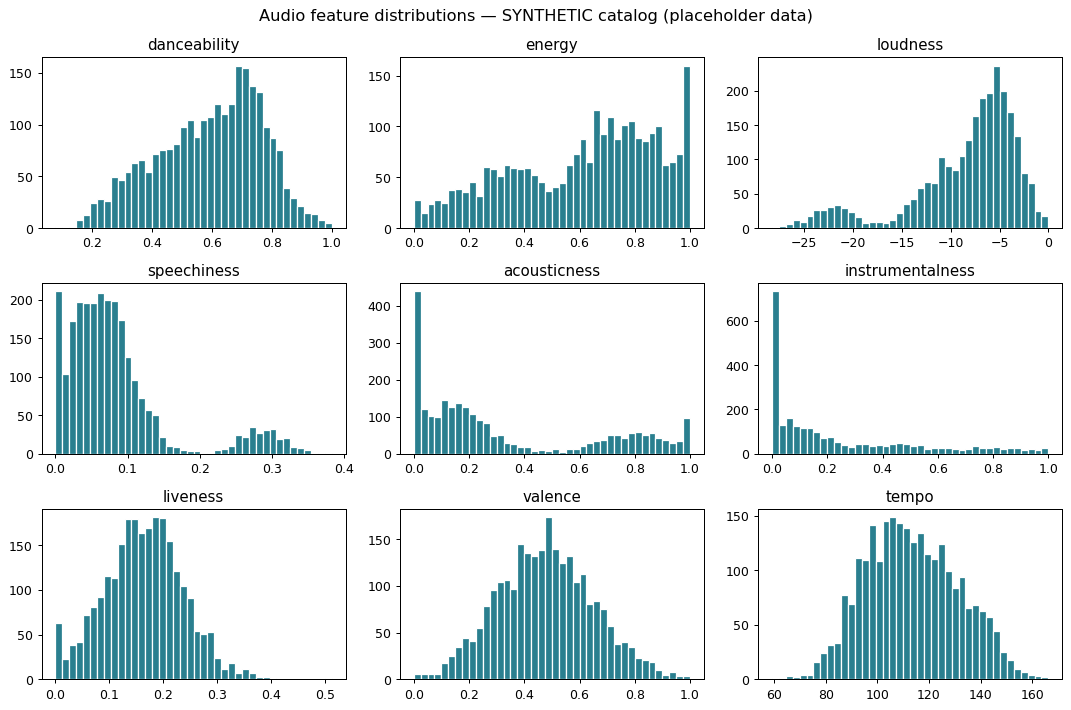

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), AUDIO_FEATURES):
    ax.hist(raw[col].dropna(), bins=40, color="#2A7F8F", edgecolor="white")
    ax.set_title(col)
fig.suptitle(f"Audio feature distributions — {DATA_SOURCE}", fontsize=13)
fig.tight_layout()

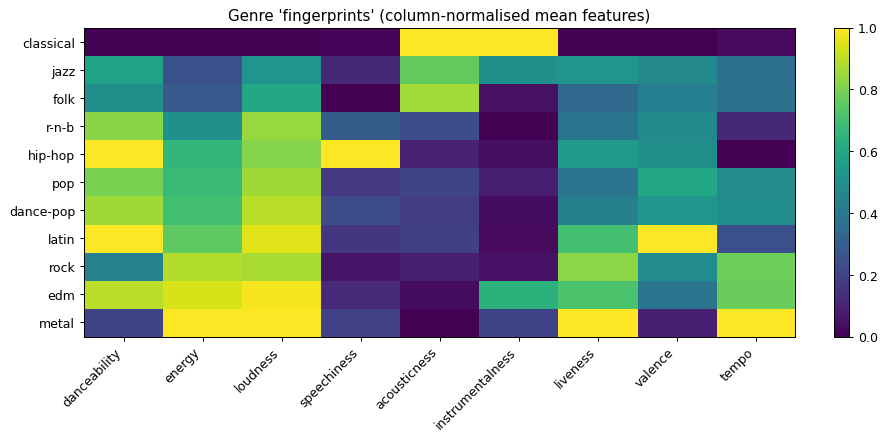

In [6]:
genre_means = (raw.groupby("track_genre")[AUDIO_FEATURES].mean()
                  .sort_values("energy"))
# Min-max normalise each column so the heatmap is readable across units
gm_norm = (genre_means - genre_means.min()) / (genre_means.max() - genre_means.min())

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(gm_norm.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(AUDIO_FEATURES)), AUDIO_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(gm_norm)), gm_norm.index)
ax.set_title("Genre 'fingerprints' (column-normalised mean features)")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout()

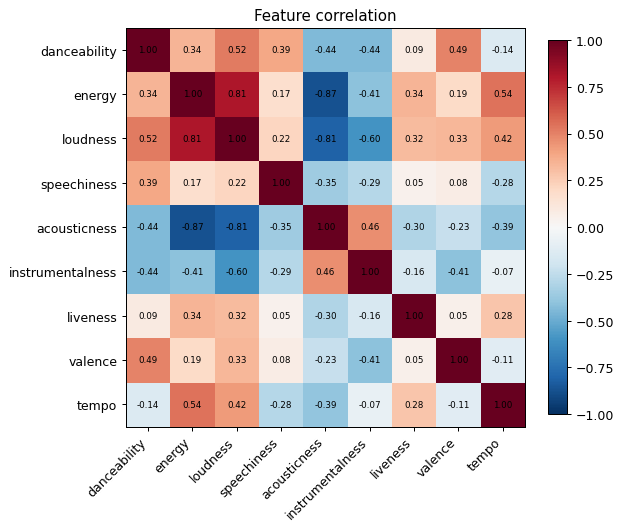

In [7]:
corr = raw[AUDIO_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(AUDIO_FEATURES)), AUDIO_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(AUDIO_FEATURES)), AUDIO_FEATURES)
for i in range(len(AUDIO_FEATURES)):
    for j in range(len(AUDIO_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Feature correlation")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()

> 💬 **Discussion prompt:** `energy`, `loudness` and `acousticness` are strongly correlated. In a Euclidean distance, correlated features effectively get *counted more than once*. Is that a bug or a feature for a music recommender? (Hint: look up Mahalanobis distance, or think about what PCA would do here.)

## Part 3 — Cleaning and feature preparation

Real catalogs are messy. The Kaggle file in particular lists the **same song multiple times under different genres**. If we leave duplicates in, the "nearest neighbor" of a song will often be... itself.

In [8]:
print("Missing values per column (non-zero only):")
print(raw.isna().sum()[lambda s: s > 0], "\n")

dup_mask = raw.duplicated(subset="track_id", keep="first")
print(f"Duplicate track_id rows: {dup_mask.sum()}")

# Which genres does a duplicated track appear under?
example_id = raw.loc[dup_mask, "track_id"].iloc[0]
raw.loc[raw["track_id"] == example_id, ["track_id", "track_name", "artists", "track_genre"]]

Missing values per column (non-zero only):
track_name    8
dtype: int64 

Duplicate track_id rows: 60


,track_id,track_name,artists,track_genre
1447,trk_01447,Hollow River,Classical Artist 23,classical
2500,trk_01447,Hollow River,Classical Artist 23,pop


In [9]:
tracks = (raw.dropna(subset=["track_name", "artists"] + AUDIO_FEATURES)
             .drop_duplicates(subset="track_id", keep="first")
             .reset_index(drop=True))

print(f"{len(raw):,} raw rows -> {len(tracks):,} clean, unique tracks")
print(f"{tracks['artists'].nunique()} artists | {tracks['track_genre'].nunique()} genres")

2,560 raw rows -> 2,492 clean, unique tracks
250 artists | 10 genres


> **Design decision to discuss:** we kept the *first* genre label for duplicated tracks. Alternatives include keeping all labels as a multi-hot vector, or picking the most specific genre. Which would you choose for a production system, and why?

Next, a helper for printing tracks consistently, and a lookup that handles ambiguous titles (many songs share a name).

In [10]:
DISPLAY_COLS = ["track_name", "artists", "track_genre", "popularity"]

def find_track(query, df=tracks):
    '''Return the row index for a track_id, or the most popular exact title match.'''
    if query in set(df["track_id"]):
        return int(df.index[df["track_id"] == query][0])
    matches = df[df["track_name"].str.lower() == str(query).lower()]
    if matches.empty:
        raise KeyError(f"No track found for {query!r}")
    if len(matches) > 1:
        print(f"Note: {len(matches)} tracks titled {query!r}; using the most popular one.")
    return int(matches["popularity"].idxmax())

# Pick a seed track to use throughout the notebook
SEED_IDX = int(tracks[tracks["track_genre"] == "jazz"]["popularity"].idxmax())
tracks.loc[[SEED_IDX], DISPLAY_COLS + AUDIO_FEATURES]

,track_name,artists,track_genre,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
1026,Wild Fire,Jazz Artist 20,jazz,100,0.561059,0.268743,-11.737692,0.013969,0.697994,0.885664,0.038063,0.568941,108.611539


## Part 4 — Why scaling matters for KNN (demo)

KNN has no learned weights. It relies entirely on the distance function. With raw features, the Euclidean distance between two tracks is

$$d(a,b) = \sqrt{\sum_{j}(a_j - b_j)^2}$$

A 20 BPM tempo difference contributes $20^2 = 400$ to the sum. A *maximal* 1.0 difference in acousticness contributes $1$. Unscaled, **tempo alone decides who your neighbors are**.

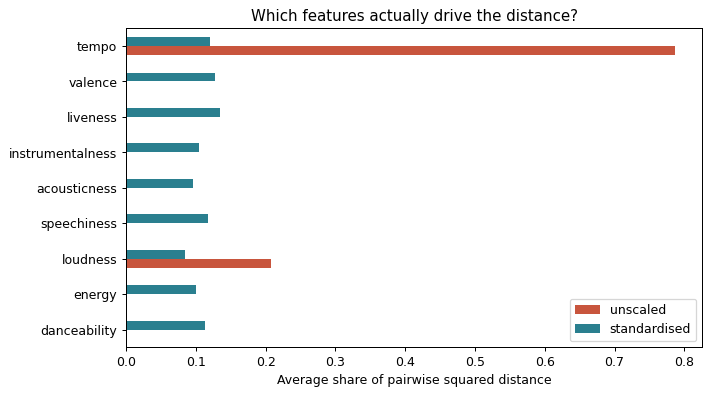

,unscaled,standardised
danceability,0.001,0.114
energy,0.001,0.100
loudness,0.208,0.084
speechiness,0.000,0.118
acousticness,0.002,0.096
instrumentalness,0.001,0.104
liveness,0.000,0.135
valence,0.001,0.128
tempo,0.786,0.121


In [11]:
X_raw = tracks[AUDIO_FEATURES].to_numpy()
X_std = StandardScaler().fit_transform(X_raw)

def contribution_share(X):
    '''Average share of squared-distance contributed by each feature across random pairs.'''
    i, j = rng.integers(0, len(X), size=(2, 5000))
    keep = i != j                                   # skip self-pairs (zero distance)
    sq = (X[i[keep]] - X[j[keep]]) ** 2
    return pd.Series((sq / sq.sum(axis=1, keepdims=True)).mean(axis=0), index=AUDIO_FEATURES)

share = pd.DataFrame({"unscaled": contribution_share(X_raw), "standardised": contribution_share(X_std)})

ax = share.plot.barh(figsize=(8, 4.5), color=["#C8553D", "#2A7F8F"])
ax.set_xlabel("Average share of pairwise squared distance")
ax.set_title("Which features actually drive the distance?")
plt.tight_layout()
share.round(3)

In [12]:
def neighbors_of(X, idx, k=5, metric="euclidean"):
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric).fit(X)
    dist, ind = nn.kneighbors(X[[idx]])
    return ind[0][1:], dist[0][1:]          # drop the query itself

for label, X in [("UNSCALED", X_raw), ("STANDARDISED", X_std)]:
    ind, _ = neighbors_of(X, SEED_IDX)
    out = tracks.loc[ind, ["track_name", "artists", "track_genre", "tempo", "acousticness"]]
    print(f"\n{label} neighbors of '{tracks.loc[SEED_IDX, 'track_name']}' ({tracks.loc[SEED_IDX, 'track_genre']}, "
          f"tempo={tracks.loc[SEED_IDX, 'tempo']:.0f}):")
    print(out.round(2).to_string())


UNSCALED neighbors of 'Wild Fire' (jazz, tempo=109):
          track_name         artists track_genre   tempo  acousticness
1171      Lunar Echo  Jazz Artist 03        jazz  109.33          0.76
1133   Frozen Letter  Jazz Artist 19        jazz  109.39          0.71
1613    Summer Dream  Folk Artist 12        folk  108.12          0.79
1551      Paper Fire  Folk Artist 18        folk  109.10          0.87
1240  Frozen Horizon  Jazz Artist 05        jazz  107.62          0.61

STANDARDISED neighbors of 'Wild Fire' (jazz, tempo=109):
           track_name         artists track_genre   tempo  acousticness
1100       Neon River  Jazz Artist 20        jazz  106.93          0.67
1078  Midnight Mirror  Jazz Artist 20        jazz  105.93          0.81
1106       Wild Heart  Jazz Artist 20        jazz  105.07          0.70
1048    Velvet Letter  Jazz Artist 20        jazz  105.91          0.74
1215        Wild Tide  Jazz Artist 20        jazz  113.99          0.73


**Takeaway:** without scaling, neighbors are chosen almost purely by tempo, so genres get mixed in arbitrarily. With `StandardScaler`, every feature gets a fair vote.

> 🧪 **Quick check:** `StandardScaler` (z-scores) vs. `MinMaxScaler` (0–1). Which is more sensitive to a single outlier track with tempo = 220? Try it in Exercise 1.

## Part 5 — Content-based recommender with `NearestNeighbors`

We'll wrap preprocessing and search in one object so the *same* transformation is applied to the catalog and to any query. This is the same fit/transform discipline you'd use for any production ML pipeline.

### 5.1 Build the index

In [13]:
scaler = StandardScaler()
X = scaler.fit_transform(tracks[AUDIO_FEATURES])

K = 10
knn_cosine = NearestNeighbors(n_neighbors=K + 1, metric="cosine", algorithm="brute").fit(X)

def recommend(query, k=K, model=knn_cosine, features=X, df=tracks, exclude_same_artist=False):
    '''Recommend k tracks similar to `query` (track_id or title).'''
    idx = find_track(query, df) if not isinstance(query, (int, np.integer)) else int(query)
    n_fetch = min(len(df), k * 4 + 1)  # over-fetch so filtering still leaves k results
    dist, ind = model.kneighbors(features[[idx]], n_neighbors=n_fetch)
    recs = df.loc[ind[0], DISPLAY_COLS].assign(distance=dist[0].round(4))
    recs = recs[recs.index != idx]
    recs = recs[recs["track_name"] != df.loc[idx, "track_name"]]   # skip alternate versions of the same title
    if exclude_same_artist:
        recs = recs[recs["artists"] != df.loc[idx, "artists"]]
    return recs.head(k)

print("Seed:", tracks.loc[SEED_IDX, DISPLAY_COLS].to_dict())
recommend(SEED_IDX)

Seed: {'track_name': 'Wild Fire', 'artists': 'Jazz Artist 20', 'track_genre': 'jazz', 'popularity': 100}


,track_name,artists,track_genre,popularity,distance
1078,Midnight Mirror,Jazz Artist 20,jazz,89,0.0215
1100,Neon River,Jazz Artist 20,jazz,83,0.0316
1106,Wild Heart,Jazz Artist 20,jazz,59,0.0517
1048,Velvet Letter,Jazz Artist 20,jazz,63,0.0578
1215,Wild Tide,Jazz Artist 20,jazz,70,0.0757
1105,Frozen River,Jazz Artist 10,jazz,72,0.0775
1166,Electric Fire,Jazz Artist 12,jazz,53,0.0798
1139,Neon Tide,Jazz Artist 12,jazz,74,0.0832
1296,Broken Signal,Classical Artist 00,classical,54,0.0845
1036,Velvet Letter,Jazz Artist 20,jazz,68,0.0845


### 5.2 Cosine vs. Euclidean: what's the difference?

* **Euclidean** measures straight-line distance, so it is sensitive to *magnitude*.
* **Cosine** measures the angle between vectors, so it asks "do these tracks deviate from the *average* track in the same directions?" (On standardised data, the origin is the average track.)

For text embeddings in RAG, cosine is the default. For standardised tabular features, either can work, so let's measure rather than guess.

### 5.3 An offline proxy metric: genre precision@k

We have no human judgments of "good recommendation", so we use a **proxy**: what fraction of the *k* recommendations share the seed track's genre? It's imperfect (a jazz fan may love a folk track), but it's cheap and lets us compare configurations.

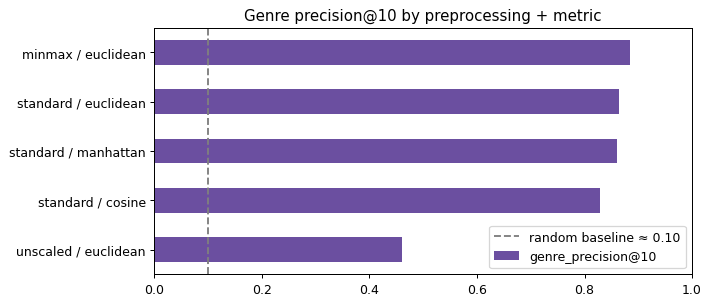

unscaled / euclidean    0.460
standard / cosine       0.829
standard / manhattan    0.860
standard / euclidean    0.864
minmax / euclidean      0.885
Name: genre_precision@10, dtype: float64

In [14]:
def genre_precision_at_k(X_feat, metric, k=10, n_queries=400, df=tracks, seed=RANDOM_STATE):
    q = np.random.default_rng(seed).choice(len(df), size=n_queries, replace=False)
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric, algorithm="brute").fit(X_feat)
    _, ind = nn.kneighbors(X_feat[q])
    genres = df["track_genre"].to_numpy()
    return (genres[ind[:, 1:]] == genres[q][:, None]).mean()

X_minmax = MinMaxScaler().fit_transform(tracks[AUDIO_FEATURES])
configs = {
    "unscaled / euclidean":     (X_raw, "euclidean"),
    "minmax / euclidean":       (X_minmax, "euclidean"),
    "standard / euclidean":     (X_std, "euclidean"),
    "standard / manhattan":     (X_std, "manhattan"),
    "standard / cosine":        (X_std, "cosine"),
}
results = pd.Series({name: genre_precision_at_k(Xf, m) for name, (Xf, m) in configs.items()},
                    name="genre_precision@10").sort_values()
chance = (tracks["track_genre"].value_counts(normalize=True) ** 2).sum()

ax = results.plot.barh(figsize=(8, 3.5), color="#6B4FA0")
ax.axvline(chance, ls="--", color="gray", label=f"random baseline ≈ {chance:.2f}")
ax.set_xlim(0, 1); ax.legend(loc="lower right"); ax.set_title("Genre precision@10 by preprocessing + metric")
plt.tight_layout()
results.round(3)

> ⚠️ **Proxy-metric trap:** Genre precision rewards *sameness*. A recommender that only ever returns tracks from the same artist would score brilliantly and bore users to tears. Real systems balance **relevance** against **diversity**, **novelty**, and **coverage**. Let's measure two of those.

### 5.4 Relevance vs. diversity: adding genre as a feature

What if we add the genre label (one-hot encoded) as extra features, with a tunable weight? `ColumnTransformer` lets us build this cleanly.

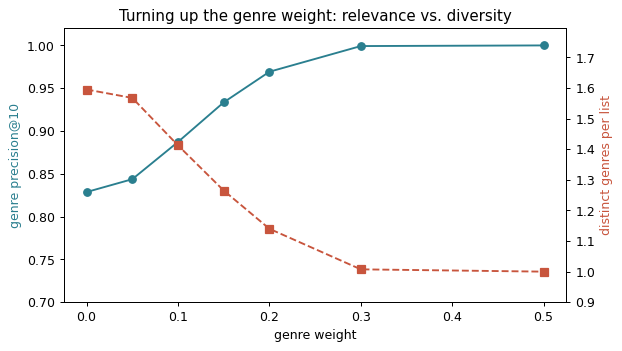

,genre_precision@10,distinct_genres@10
genre_weight,,
0.00,0.829,1.595
0.05,0.844,1.568
0.10,0.887,1.412
0.15,0.934,1.265
0.20,0.969,1.140
0.30,0.999,1.008
0.50,1.000,1.000


In [15]:
def build_feature_pipeline(genre_weight=0.0):
    '''Standardise audio features; one-hot genre scaled by `genre_weight`.'''
    transformers = [("audio", StandardScaler(), AUDIO_FEATURES)]
    if genre_weight > 0:
        transformers.append(("genre", Pipeline([
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ("w", StandardScaler(with_mean=False)),           # unit variance first...
        ]), ["track_genre"]))
    return ColumnTransformer(transformers), genre_weight

def featurise(df, genre_weight):
    ct, w = build_feature_pipeline(genre_weight)
    Z = ct.fit_transform(df)
    if w > 0:
        Z[:, len(AUDIO_FEATURES):] *= w                      # ...then apply the weight
    return Z

def genre_diversity(X_feat, metric="cosine", k=10, n_queries=400, df=tracks, seed=RANDOM_STATE):
    '''Average number of distinct genres in each top-k list (1 = a single-genre "bubble").'''
    q = np.random.default_rng(seed).choice(len(df), size=n_queries, replace=False)
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric, algorithm="brute").fit(X_feat)
    _, ind = nn.kneighbors(X_feat[q])
    genres = df["track_genre"].to_numpy()
    return np.mean([len(set(genres[row[1:]])) for row in ind])

rows = []
for w in [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
    Z = featurise(tracks, w)
    rows.append({"genre_weight": w,
                 "genre_precision@10": genre_precision_at_k(Z, "cosine"),
                 "distinct_genres@10": genre_diversity(Z)})
tradeoff = pd.DataFrame(rows).set_index("genre_weight")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(tradeoff.index, tradeoff["genre_precision@10"], "o-", color="#2A7F8F", label="genre precision@10")
ax1.set_ylabel("genre precision@10", color="#2A7F8F"); ax1.set_ylim(0.7, 1.02); ax1.set_xlabel("genre weight")
ax2 = ax1.twinx()
ax2.plot(tradeoff.index, tradeoff["distinct_genres@10"], "s--", color="#C8553D", label="distinct genres per list")
ax2.set_ylabel("distinct genres per list", color="#C8553D"); ax2.set_ylim(0.9, tradeoff["distinct_genres@10"].max() + 0.2)
ax1.set_title("Turning up the genre weight: relevance vs. diversity")
fig.tight_layout()
tradeoff.round(3)

> 💬 **Discussion prompt:** Even a small genre weight drives precision@10 to ~1.0 and collapses each list to a single genre. We have essentially built a genre filter with extra steps and killed cross-genre discovery. Where would *you* set this dial for (a) a "More like this" button, (b) a weekly discovery playlist? This is a **product decision**, not a modelling one. Metrics inform it; they don't make it.

### 5.5 Playlist-level recommendations

Users rarely have one seed song. A simple, strong baseline: average the seed tracks' vectors into a **"taste centroid"** and query around it.

In [16]:
def recommend_for_playlist(seed_indices, k=K, features=X, df=tracks):
    centroid = features[seed_indices].mean(axis=0, keepdims=True)
    nn = NearestNeighbors(n_neighbors=k + len(seed_indices), metric="cosine").fit(features)
    dist, ind = nn.kneighbors(centroid)
    recs = df.loc[ind[0], DISPLAY_COLS].assign(distance=dist[0].round(4))
    return recs[~recs.index.isin(seed_indices)].head(k)

# A 'late-night' playlist: 3 jazz + 2 folk tracks
playlist = (tracks[tracks.track_genre == "jazz"].sample(3, random_state=1).index.tolist() +
            tracks[tracks.track_genre == "folk"].sample(2, random_state=1).index.tolist())
print("Seed playlist:")
print(tracks.loc[playlist, DISPLAY_COLS].to_string(), "\n")
recommend_for_playlist(playlist)

Seed playlist:
          track_name         artists track_genre  popularity
1066  Endless Garden  Jazz Artist 10        jazz          73
1246   Golden Garden  Jazz Artist 01        jazz          33
1209       Wild Fire  Jazz Artist 01        jazz          38
1564  Midnight Dream  Folk Artist 09        folk          72
1744  Summer Horizon  Folk Artist 12        folk           9 



,track_name,artists,track_genre,popularity,distance
1124,Wild Road,Jazz Artist 05,jazz,21,0.0487
1071,Summer Heart,Jazz Artist 18,jazz,35,0.0567
1154,Hollow City,Jazz Artist 07,jazz,67,0.0610
1098,Paper Horizon,Jazz Artist 03,jazz,46,0.0675
1031,Crimson Sky,Jazz Artist 05,jazz,38,0.0742
1011,Silent Fire,Jazz Artist 10,jazz,80,0.0786
1116,Endless City,Jazz Artist 12,jazz,62,0.0804
1142,Broken Echo,Jazz Artist 18,jazz,26,0.0870
1057,Hollow Fire,Jazz Artist 18,jazz,34,0.0904
1099,Neon City,Jazz Artist 19,jazz,16,0.0911


> 🧪 **Think about it:** What happens to the centroid of a playlist that mixes metal and classical? It lands somewhere in the middle of feature space that neither genre occupies, and you may get recommendations that match *neither* taste. Exercise 3 asks you to fix this.

## Part 6 — Choosing *k* with `KNeighborsClassifier` + cross-validation

`NearestNeighbors` is unsupervised, so there's no label to tune against. But we can borrow a supervised framing: **predict a track's genre from its k nearest neighbors**. The *k* (and weighting) that best predicts genre tells us how "local" musical similarity is in this dataset.

This also makes the **bias–variance trade-off** tangible:

* **k = 1**: each prediction depends on a single neighbor → low bias, high variance (noisy).
* **Large k**: predictions average over a large neighborhood → smooth, but eventually blurs genres together (high bias).

In [17]:
X_tr, X_te, y_tr, y_te = train_test_split(tracks[AUDIO_FEATURES], tracks["track_genre"],
                                          test_size=0.2, stratify=tracks["track_genre"],
                                          random_state=RANDOM_STATE)

pipe = Pipeline([("scale", StandardScaler()),
                 ("knn", KNeighborsClassifier())])

param_grid = {"knn__n_neighbors": [1, 3, 5, 9, 15, 25, 40, 60, 100],
              "knn__weights": ["uniform", "distance"],
              "knn__metric": ["euclidean", "cosine"]}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", return_train_score=True)
search.fit(X_tr, y_tr)

print("Best params:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.3f}")
print(f"Held-out test accuracy: {search.score(X_te, y_te):.3f}")

Best params: {'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__weights': 'distance'}
Best CV accuracy: 0.926
Held-out test accuracy: 0.912


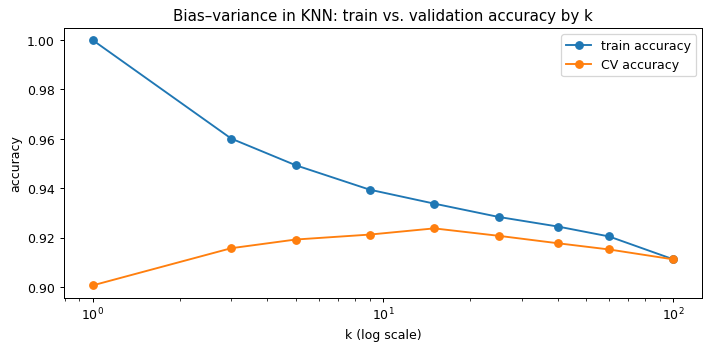

In [18]:
cvres = pd.DataFrame(search.cv_results_)
sub = cvres[(cvres.param_knn__weights == "uniform") & (cvres.param_knn__metric == search.best_params_["knn__metric"])]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sub.param_knn__n_neighbors.astype(int), sub.mean_train_score, "o-", label="train accuracy")
ax.plot(sub.param_knn__n_neighbors.astype(int), sub.mean_test_score, "o-", label="CV accuracy")
ax.set_xscale("log"); ax.set_xlabel("k (log scale)"); ax.set_ylabel("accuracy")
ax.set_title("Bias–variance in KNN: train vs. validation accuracy by k")
ax.legend(); plt.tight_layout()

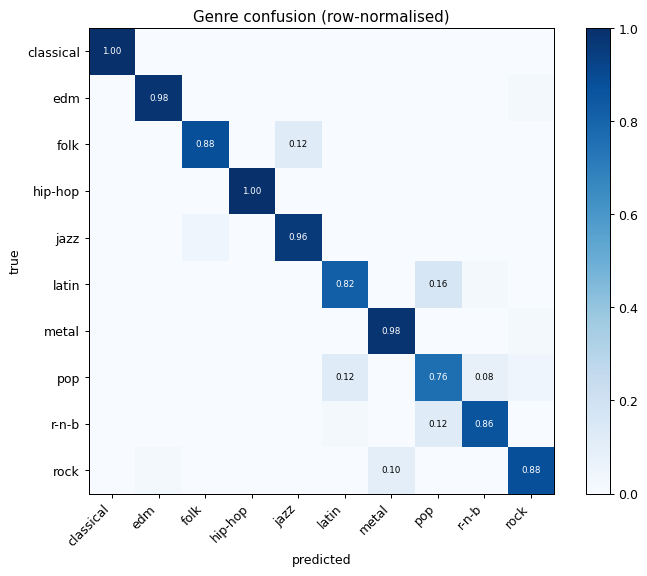

In [19]:
from sklearn.metrics import confusion_matrix
y_pred = search.predict(X_te)
labels = sorted(tracks["track_genre"].unique())
cm = pd.DataFrame(confusion_matrix(y_te, y_pred, labels=labels, normalize="true"), index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm.iloc[i, j] >= 0.05:
            ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm.iloc[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Genre confusion (row-normalised)")
fig.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout()

**Reading the confusion matrix:** off-diagonal clusters show which genres are *acoustically* adjacent. Those confusions are exactly where a content-based recommender will produce cross-genre suggestions. Whether that's a bug (wrong genre) or a feature (serendipity) depends on the user.

> 📌 On the real Kaggle data with 114 genres, expect much lower accuracy. Many genres (e.g., "indie-pop" vs. "pop") are marketing labels, not acoustic categories. That's a useful lesson in itself.

## Part 7 — Item-based collaborative filtering and offline evaluation

Content-based filtering knows what tracks *sound like*. **Collaborative filtering (CF)** knows what tracks *people listen to together*, with no audio features needed. It's how "fans also like" works.

**Item-based CF with KNN:**
1. Build a sparse **item × user** matrix of listen counts.
2. Two tracks are similar if their column vectors of listeners are similar (cosine).
3. To recommend for a user, score each candidate track by its similarity to the tracks the user already plays.

### 7.1 Simulate listening histories

Spotify doesn't publish user-level data, so we simulate users with 1–2 favourite genres and a handful of favourite artists. (Public alternatives for real interaction data: the Million Playlist Dataset, or Last.fm listening datasets. Verify current access terms before assigning.)

In [20]:
def simulate_listens(df, n_users=2000, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    genres = df["track_genre"].unique()
    pop_weight = (df["popularity"].to_numpy() + 5) / 100      # popular tracks get played more
    rows = []
    for u in range(n_users):
        favs = r.choice(genres, size=r.integers(1, 3), replace=False)
        fav_artists = r.choice(df.loc[df.track_genre.isin(favs), "artists"].unique(), size=4, replace=False)
        w = (np.where(df["track_genre"].isin(favs), 1.0, 0.03)
             * np.where(df["artists"].isin(fav_artists), 6.0, 1.0) * pop_weight)
        n_tracks = r.integers(15, 60)
        chosen = r.choice(len(df), size=n_tracks, replace=False, p=w / w.sum())
        for t in chosen:
            rows.append((u, t, int(r.geometric(0.25))))        # play count
    return pd.DataFrame(rows, columns=["user", "track_idx", "plays"])

listens = simulate_listens(tracks)
n_users, n_items = listens.user.nunique(), len(tracks)
print(f"{len(listens):,} (user, track) interactions | {n_users} users | {n_items:,} tracks")
print(f"Matrix density: {len(listens) / (n_users * n_items):.2%}  (real systems are far sparser)")
listens.head()

73,781 (user, track) interactions | 2000 users | 2,492 tracks
Matrix density: 1.48%  (real systems are far sparser)


,user,track_idx,plays
0,0,2032,2
1,0,1936,2
2,0,1947,1
3,0,1764,1
4,0,1862,3


### 7.2 Train/test split: leave-one-out

For each user, hide **one** track they listened to. A good recommender should rank that hidden track in its top 10. This is **Hit Rate@10** (a.k.a. Recall@10 with one held-out item).

In [21]:
test = listens.groupby("user").sample(1, random_state=RANDOM_STATE)
train = listens.drop(test.index)

def item_user_matrix(interactions, n_items, n_users):
    # log(1 + plays) dampens heavy repeat listeners
    return csr_matrix((np.log1p(interactions.plays.to_numpy()),
                       (interactions.track_idx.to_numpy(), interactions.user.to_numpy())),
                      shape=(n_items, n_users))

R = item_user_matrix(train, n_items, n_users)          # items x users, sparse
print("Item-user matrix:", R.shape, f"with {R.nnz:,} non-zeros")

CF_NEIGHBORS = 30
cf_knn = NearestNeighbors(n_neighbors=CF_NEIGHBORS + 1, metric="cosine", algorithm="brute").fit(R)

Item-user matrix: (2492, 2000) with 71,781 non-zeros


In [22]:
user_hist = train.groupby("user")["track_idx"].apply(np.array).to_dict()

# Precompute every item's neighbor list once (cheap at this size)
cf_dist, cf_ind = cf_knn.kneighbors(R)
cf_sim = 1 - cf_dist
content_dist, content_ind = knn_cosine.kneighbors(X, n_neighbors=CF_NEIGHBORS + 1)
content_sim = 1 - content_dist

def score_from_neighbors(history, nbr_ind, nbr_sim, n_items=n_items):
    '''Sum similarity of each candidate to every track in the user's history.'''
    scores = np.zeros(n_items)
    for t in history:
        np.add.at(scores, nbr_ind[t, 1:], nbr_sim[t, 1:])
    scores[history] = -np.inf                               # never re-recommend known tracks
    return scores

def top_n(scores, n=10):
    return np.argpartition(-scores, n)[:n]

def recommend_cf(user, n=10):
    recs = top_n(score_from_neighbors(user_hist[user], cf_ind, cf_sim), n)
    return tracks.loc[recs, DISPLAY_COLS]

u = 7
print(f"User {u} listens mostly to:", tracks.loc[user_hist[u], "track_genre"].value_counts().head(3).to_dict())
recommend_cf(u)

User 7 listens mostly to: {'rock': 42, 'latin': 3, 'hip-hop': 2}


,track_name,artists,track_genre,popularity
414,Neon Engine,Rock Artist 24,rock,62
257,Silent Heart,Rock Artist 19,rock,86
314,Crimson Signal,Rock Artist 00,rock,65
374,Silent Road,Rock Artist 07,rock,82
332,Paper Letter,Rock Artist 24,rock,70
352,Endless City,Rock Artist 10,rock,56
441,Midnight Sky,Rock Artist 08,rock,59
307,Endless Signal,Rock Artist 01,rock,39
305,Hollow Signal,Rock Artist 07,rock,66
467,Endless City,Rock Artist 11,rock,65


### 7.3 Compare against baselines

Never report a recommender's score without baselines. We'll compare:

* **Random**: sample 10 unseen tracks. (The floor.)
* **Most popular**: the 10 most-played tracks the user hasn't heard. (Surprisingly hard to beat.)
* **Content-based KNN**: audio-feature neighbors of the user's history (Part 5).
* **Item-based CF KNN**: co-listening neighbors (this part).
* **Hybrid**: a simple blend of the two normalised scores.

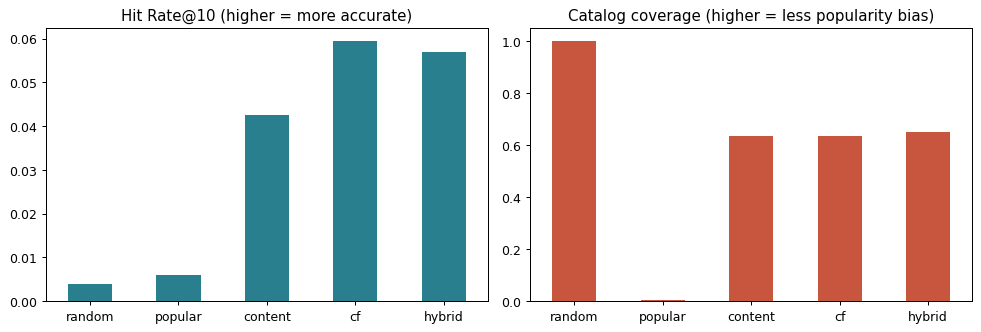

,hit_rate@10,catalog_coverage
random,0.004,1.000
popular,0.006,0.005
content,0.042,0.635
cf,0.060,0.632
hybrid,0.057,0.651


In [23]:
global_pop = np.bincount(train.track_idx, weights=train.plays, minlength=n_items).astype(float)

def normalise(s):
    finite = np.isfinite(s)
    out = np.full_like(s, -np.inf)
    if finite.any() and s[finite].max() > 0:
        out[finite] = s[finite] / s[finite].max()
    return out

def evaluate(strategy, n=10, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    hits, rec_items = [], set()
    for user, held_out in zip(test.user, test.track_idx):
        hist = user_hist[user]
        if strategy == "random":
            s = r.random(n_items); s[hist] = -np.inf
        elif strategy == "popular":
            s = global_pop.copy(); s[hist] = -np.inf
        elif strategy == "content":
            s = score_from_neighbors(hist, content_ind, content_sim)
        elif strategy == "cf":
            s = score_from_neighbors(hist, cf_ind, cf_sim)
        elif strategy == "hybrid":
            s = 0.7 * normalise(score_from_neighbors(hist, cf_ind, cf_sim)) + \
                0.3 * normalise(score_from_neighbors(hist, content_ind, content_sim))
        recs = top_n(s, n)
        hits.append(held_out in recs)
        rec_items.update(recs.tolist())
    return {"hit_rate@10": np.mean(hits), "catalog_coverage": len(rec_items) / n_items}

eval_df = pd.DataFrame({s: evaluate(s) for s in ["random", "popular", "content", "cf", "hybrid"]}).T

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
eval_df["hit_rate@10"].plot.bar(ax=axes[0], color="#2A7F8F", rot=0, title="Hit Rate@10 (higher = more accurate)")
eval_df["catalog_coverage"].plot.bar(ax=axes[1], color="#C8553D", rot=0, title="Catalog coverage (higher = less popularity bias)")
plt.tight_layout()
eval_df.round(3)

**How to read this:**

* **Hit Rate** measures accuracy on the hidden track.
* **Catalog coverage** is the share of the catalog that ever gets recommended to *anyone*. The popularity baseline recommends the same handful of hits to everybody. That's the **popularity-bias / rich-get-richer** problem that real platforms actively fight.
* Absolute hit rates look low because the held-out track is one of ~250 near-interchangeable tracks in its genre. Compare strategies *relative* to the random and popularity baselines, not to 100%.
* CF typically wins on accuracy when interaction data is plentiful; content-based wins in **cold-start** (a brand-new track has audio features on day one but zero listeners). That complementarity is why production systems are hybrids.

> 📌 **Placeholder-data flag:** these numbers depend heavily on how the synthetic users were generated (they literally *choose* tracks by genre and artist). Treat them as a demonstration of the evaluation *method*, not as evidence of which algorithm is better.

## Part 8 — Scaling up: brute force vs. trees vs. ANN

Exact KNN compares the query against **every** item: $O(N \cdot d)$ per query. Spotify's catalog is ~100M tracks. scikit-learn offers tree indexes (`kd_tree`, `ball_tree`) that prune the search in low dimensions, but they degrade toward brute force as dimensionality grows (the **curse of dimensionality**).

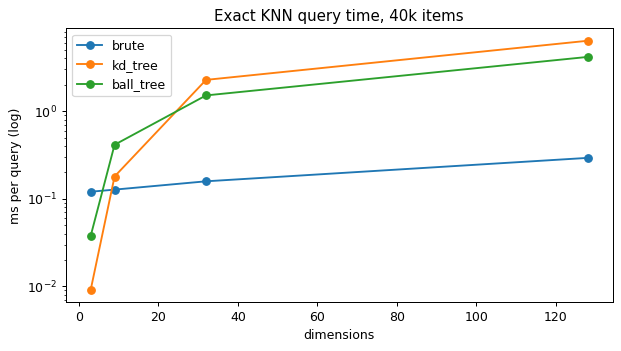

,brute,kd_tree,ball_tree
dimensions,,,
3,0.120,0.009,0.038
9,0.127,0.180,0.413
32,0.158,2.278,1.514
128,0.293,6.372,4.166


In [24]:
def time_queries(n_items, dim, algorithm, n_queries=200, k=10, seed=0):
    r = np.random.default_rng(seed)
    data = r.normal(size=(n_items, dim)).astype(np.float32)
    q = r.normal(size=(n_queries, dim)).astype(np.float32)
    nn = NearestNeighbors(n_neighbors=k, algorithm=algorithm).fit(data)
    t0 = time.perf_counter(); nn.kneighbors(q); return (time.perf_counter() - t0) / n_queries * 1000

timing = pd.DataFrame(
    {algo: {dim: time_queries(40_000, dim, algo) for dim in [3, 9, 32, 128]}
     for algo in ["brute", "kd_tree", "ball_tree"]})
timing.index.name = "dimensions"

ax = timing.plot(marker="o", logy=True, figsize=(7, 4))
ax.set_ylabel("ms per query (log)"); ax.set_title("Exact KNN query time, 40k items")
plt.tight_layout()
timing.round(3)

**Takeaways:**

* Trees only win clearly at very low dimension. Around 10 dimensions (our audio features) scikit-learn's vectorised brute force usually catches up, and beyond that trees are *slower* than brute force. (Exact timings vary by machine; the shape of the curves is the lesson.)
* At 128+ dimensions, which is typical of learned embeddings and *very* typical of text embeddings (768–3,072 dims), exact search stops being practical at scale.
* Production systems therefore use **Approximate Nearest Neighbor (ANN)** indexes: HNSW graphs, IVF clustering, product quantization. They trade a little recall for orders-of-magnitude speed. Spotify open-sourced **Annoy** and later **Voyager** for exactly this; **FAISS** (Meta) and the vector databases you'll meet in the RAG module (e.g., Chroma, pgvector, Pinecone, Weaviate) are built on the same ideas.

> 🔗 **Bridge to Module: RAG.** Replace "track" with "document chunk", "audio features" with "text embedding", and "recommend similar songs" with "retrieve relevant context". You have just built the retrieval half of a RAG system. The questions you asked here (which metric? normalised or not? how many neighbors? how do we evaluate without labels? how do we keep results diverse?) are the same questions you'll ask there.

## Part 9 — Packaging: a reusable `TrackRecommender` class

Notebook functions are great for exploration. For anything you'd deploy, bundle preprocessing and index into one object with a clear `fit` / `recommend` API, so a query can never be scaled differently from the catalog.

In [25]:
class TrackRecommender:
    '''Content-based KNN recommender over audio features.

    Parameters
    ----------
    features : list[str]  audio feature columns to use
    k        : int        default number of recommendations
    metric   : str        any metric supported by sklearn NearestNeighbors
    '''

    def __init__(self, features=AUDIO_FEATURES, k=10, metric="cosine"):
        self.features, self.k, self.metric = list(features), k, metric

    def fit(self, catalog: pd.DataFrame):
        missing = set(self.features) - set(catalog.columns)
        if missing:
            raise ValueError(f"Catalog is missing columns: {sorted(missing)}")
        self.catalog_ = catalog.reset_index(drop=True)
        self.scaler_ = StandardScaler().fit(self.catalog_[self.features])
        self.X_ = self.scaler_.transform(self.catalog_[self.features])
        self.index_ = NearestNeighbors(metric=self.metric, algorithm="brute").fit(self.X_)
        return self

    def _search(self, vectors, k, exclude):
        dist, ind = self.index_.kneighbors(vectors, n_neighbors=min(len(self.catalog_), k + len(exclude) + 5))
        out = self.catalog_.loc[ind[0], DISPLAY_COLS].assign(distance=dist[0].round(4))
        return out[~out.index.isin(exclude)].head(k)

    def similar_to(self, track_id: str, k=None):
        hits = self.catalog_.index[self.catalog_["track_id"] == track_id]
        if hits.empty:
            raise KeyError(track_id)
        return self._search(self.X_[hits[:1]], k or self.k, exclude=list(hits))

    def for_features(self, feature_dict: dict, k=None):
        '''Cold-start query: recommend from raw feature values (e.g., a brand-new upload).'''
        row = pd.DataFrame([feature_dict])[self.features]
        return self._search(self.scaler_.transform(row), k or self.k, exclude=[])

rec = TrackRecommender(k=5).fit(tracks)
seed_id = tracks.loc[SEED_IDX, "track_id"]
print(f"Similar to {seed_id}:")
display(rec.similar_to(seed_id))

print("Cold start — a brand-new, high-energy, danceable upload with no listeners yet:")
rec.for_features({"danceability": 0.8, "energy": 0.9, "loudness": -4, "speechiness": 0.06,
                  "acousticness": 0.02, "instrumentalness": 0.6, "liveness": 0.15,
                  "valence": 0.5, "tempo": 128})

Similar to trk_01027:


,track_name,artists,track_genre,popularity,distance
1078,Midnight Mirror,Jazz Artist 20,jazz,89,0.0215
1100,Neon River,Jazz Artist 20,jazz,83,0.0316
1106,Wild Heart,Jazz Artist 20,jazz,59,0.0517
1048,Velvet Letter,Jazz Artist 20,jazz,63,0.0578
1215,Wild Tide,Jazz Artist 20,jazz,70,0.0757


Cold start — a brand-new, high-energy, danceable upload with no listeners yet:


,track_name,artists,track_genre,popularity,distance
829,Neon Heart,Edm Artist 10,edm,66,0.0339
777,Electric Tide,Edm Artist 15,edm,40,0.0384
865,Neon Horizon,Edm Artist 24,edm,18,0.0453
770,Midnight Heart,Edm Artist 06,edm,84,0.0481
790,Velvet Echo,Edm Artist 06,edm,73,0.0484


To persist the fitted model for an API or app:

```python
import joblib
joblib.dump(rec, "track_recommender.joblib")
rec = joblib.load("track_recommender.joblib")
```

> ⚠️ Only `joblib.load` files you created yourself: unpickling can execute arbitrary code. Pin your scikit-learn version, since pickles are not guaranteed to load across versions.

---
## Summary

| Concept | What you did | Where it shows up next |
|---|---|---|
| Similarity as distance | Tracks as 9-D vectors | Documents as embedding vectors (RAG) |
| Scaling | Showed tempo dominates unscaled distance | Embedding normalisation before cosine search |
| Metric choice | Euclidean vs. Manhattan vs. cosine | Vector DB distance settings |
| Choosing *k* | CV sweep, bias–variance curve | `top_k` retrieval parameter |
| Offline evaluation | Proxy precision, Hit Rate@10, coverage, baselines | Retrieval recall@k, RAG eval sets |
| Hybrid systems | Content + CF blend, cold start | Hybrid (keyword + vector) retrieval |
| Scale | Brute vs. trees vs. ANN | HNSW / IVF indexes in vector stores |

---
## In-class exercises (Session 2, ~40 min, pairs)

**Exercise 1 — Scaler robustness (10 min).** Add a single outlier track with `tempo=220` and `loudness=0` to the catalog. Compare how `StandardScaler`, `MinMaxScaler`, and `RobustScaler` change the neighbors of a normal pop track. Write two sentences on which you'd ship and why.

**Exercise 2 — Feature weighting (10 min).** A product manager says "users care about *mood* more than anything." Modify the pipeline so `valence` and `energy` count 2× in the distance. Show the change in genre precision@10 and pick one seed track where the recommendations visibly improve (or get worse).

**Exercise 3 — Mixed-taste playlists (15 min).** The centroid approach fails for a metal + classical playlist. Implement a **multi-seed** alternative: retrieve neighbors for each seed separately, then merge the lists by round-robin or by summed similarity. Compare both approaches on a mixed playlist.

**Exercise 4 — Explain a recommendation (5 min).** Write `explain(seed_idx, rec_idx)` that returns the three features where the two tracks are most similar and the one where they differ most (in standardised units). Explainability is increasingly a regulatory expectation for recommender systems.

In [26]:
# Exercise scaffold — Exercise 4 starter
def explain(seed_idx, rec_idx, X_feat=X_std, features=AUDIO_FEATURES):
    '''Return (top-3 most similar features, most different feature).'''
    diff = np.abs(X_feat[seed_idx] - X_feat[rec_idx])
    # TODO: use np.argsort on `diff` to find the 3 smallest and the 1 largest differences
    raise NotImplementedError("Complete Exercise 4")

---
## Take-home assignment: "Beyond Genre Precision" (individual, 1 week)

Using the **real Kaggle dataset** (Option A in Part 1), build and evaluate a recommender that improves on the Part 5 baseline. Your submission must include:

1. **Data preparation** (dedupe strategy justified; at least one engineered feature such as `duration_min`, a `key`/`mode` encoding, or an `explicit` flag).
2. **At least two recommender variants** (e.g., different feature sets/weights, metrics, or a PCA-reduced space), plus the Part 5 baseline.
3. **An evaluation section** with at least **one relevance metric** and **one beyond-accuracy metric** (diversity, novelty = mean inverse popularity, or coverage), with a baseline for each.
4. **A qualitative review**: pick 5 seed tracks you actually know, show the top-10 for each variant, and critique them honestly as a listener.
5. **A 300–500 word reflection**: where did the proxy metrics and your ears disagree? What does that imply about evaluating recommenders (and RAG retrievers) in production?

Deliverables: a single executed notebook (`lastname_knn_recommender.ipynb`) that runs top-to-bottom without errors, and a `requirements.txt`.

### Grading rubric (100 points)

| Criterion | Excellent (full) | Proficient (~75%) | Developing (~50%) | Missing (0) | Points |
|---|---|---|---|---|---|
| **Data preparation** | Dedupe, missing values and scaling handled with explicit justification; engineered feature motivated by EDA | Handled correctly, thin justification | Partially handled; scaling or dedupe missing | Not done | 15 |
| **Model variants** | ≥2 well-motivated variants; pipeline prevents train/query inconsistency | 2 variants, some ad hoc choices | 1 variant beyond baseline | Baseline only | 20 |
| **Quantitative evaluation** | Relevance + beyond-accuracy metrics, baselines, fixed seeds, results tabulated and visualised | Metrics and baselines present, limited analysis | Single metric or no baselines | None | 25 |
| **Qualitative review** | 5 seeds × all variants, specific listener-level critique linked back to features | Reviews present but generic | Fewer than 5 seeds or no critique | None | 15 |
| **Reflection** | Insightful discussion of proxy-metric limits with explicit link to retrieval/RAG evaluation | Reasonable discussion, weak link to RAG | Superficial | None | 15 |
| **Code quality & reproducibility** | Runs top-to-bottom, clear functions/docstrings, pinned requirements | Runs with minor issues | Requires manual fixes | Does not run | 10 |

**Challenge extensions (up to +10 bonus):** replace exact KNN with an ANN library (Annoy, Voyager, or FAISS) and report recall@10 vs. the exact results plus speed-up; or implement a hybrid content + CF model using a public interaction dataset and demonstrate cold-start behaviour.